# Predicting Concrete Compressive Strength Using Machine Learning

**Advanced Artificial Intelligence – Final Project**

## 1. Introduction

Concrete is widely used in construction, and its compressive strength is important for structural safety. The strength of concrete depends on its ingredients and curing age.

In this project, I will use machine learning to predict concrete compressive strength based on its mixture components and age.

I will compare two machine learning models, Linear Regression and Random Forest, to find which model makes more accurate predictions.

### 1.1 Problem Identification

**What problem am I trying to solve?**

I want to predict concrete compressive strength using machine learning instead of relying only on laboratory testing.

**Why is this problem important?**

Concrete strength is important for construction safety. Laboratory testing requires time and equipment, so estimating strength using machine learning may help save time.

**Who would benefit from this solution?**

Civil engineers, concrete manufacturers, and researchers could benefit from this model when studying concrete mixtures.

**How can machine learning help?**

Machine learning can learn patterns from concrete ingredients and curing age to estimate compressive strength. I will compare Linear Regression and Random Forest to find the better model.

**What will my model predict?**

The model will predict concrete compressive strength as a numerical value measured in megapascals (MPa).

## 2. Dataset

The dataset is from the UCI Machine Learning Repository. It contains 1,030 concrete samples with eight input features and one target variable: concrete compressive strength (MPa).

In [1]:
# Install the Excel reader
!pip -q install xlrd

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset directly from UCI
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    with archive.open("Concrete_Data.xls") as file:
        df = pd.read_excel(file, engine="xlrd")

# Display dataset
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1030, 9)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


## 3. Data Exploration

Before training the machine learning models, I will explore the dataset to understand its structure and check for possible data quality issues.

In [ ]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names and data types
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (1030, 9)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Co

### 3.1 Descriptive Statistics

I will use descriptive statistics to understand the distribution and range of the concrete ingredients, curing age, and compressive strength.

In [ ]:
# Display descriptive statistics
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Cement (component 1)(kg in a m^3 mixture),1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
Blast Furnace Slag (component 2)(kg in a m^3 mixture),1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
Fly Ash (component 3)(kg in a m^3 mixture),1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
Water (component 4)(kg in a m^3 mixture),1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
Superplasticizer (component 5)(kg in a m^3 mixture),1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
Coarse Aggregate (component 6)(kg in a m^3 mixture),1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
Fine Aggregate (component 7)(kg in a m^3 mixture),1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
Age (day),1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
"Concrete compressive strength(MPa, megapascals)",1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


### Descriptive Statistics Findings

The dataset contains concrete samples with different mixture compositions and curing ages. The average compressive strength is 35.82 MPa, with values ranging from 2.33 to 82.60 MPa. The curing age ranges from 1 to 365 days.

Some ingredients have zero values because they are not included in every concrete mixture. The dataset shows enough variation to explore the relationships between the ingredients, curing age, and concrete strength.

### 3.2 Distribution of Concrete Compressive Strength

I will create a histogram to understand how concrete compressive strength values are distributed in the dataset.

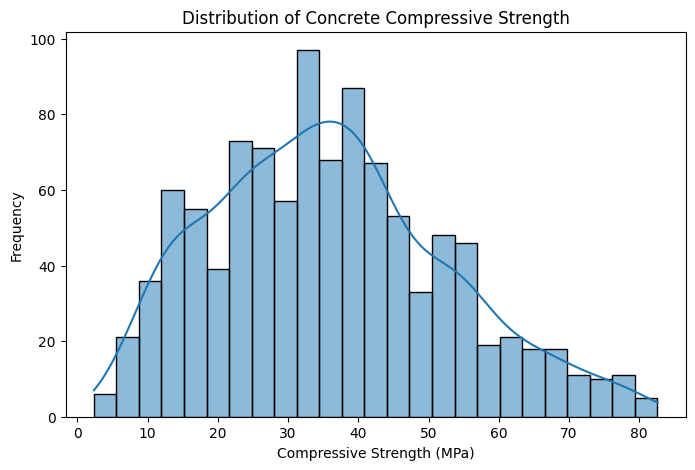

In [ ]:
# Distribution of concrete compressive strength

plt.figure(figsize=(8, 5))

sns.histplot(df.iloc[:, -1], bins=25, kde=True)

plt.title('Distribution of Concrete Compressive Strength')
plt.xlabel('Compressive Strength (MPa)')
plt.ylabel('Frequency')

plt.show()

### Histogram Findings

The histogram shows that most concrete samples have compressive strength values between 20 and 50 MPa. The highest concentration is around 30–40 MPa. The distribution is slightly right-skewed, with fewer samples having very high strength values.

### 3.3 Relationship Between Curing Age and Compressive Strength

I will use a scatter plot to explore the relationship between concrete curing age and compressive strength.

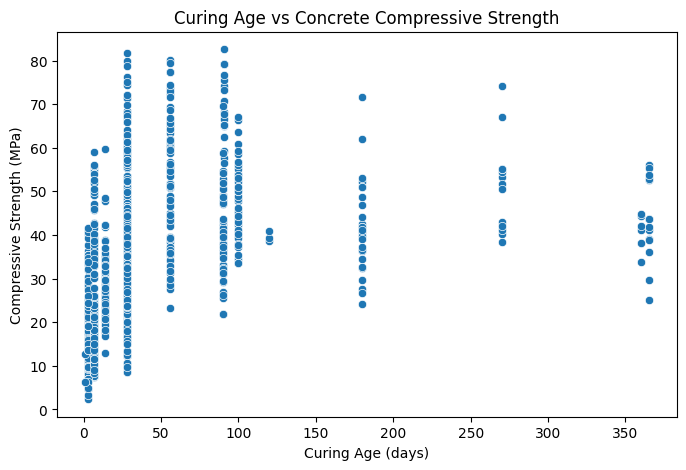

In [ ]:
# Relationship between curing age and concrete strength

plt.figure(figsize=(8, 5))

sns.scatterplot(x=df.iloc[:, 7], y=df.iloc[:, -1])

plt.title('Curing Age vs Concrete Compressive Strength')
plt.xlabel('Curing Age (days)')
plt.ylabel('Compressive Strength (MPa)')

plt.show()

### Curing Age vs. Strength Findings

The scatter plot shows that concrete strength generally increases during the early curing period. However, there is a wide range of strength values at the same curing age. This is because concrete mixtures contain different amounts of cement, water, and other materials. Therefore, curing age alone is not enough to predict concrete strength accurately.

### 3.4 Correlation Analysis

I will use a correlation heatmap to examine the relationships between concrete ingredients, curing age, and compressive strength.

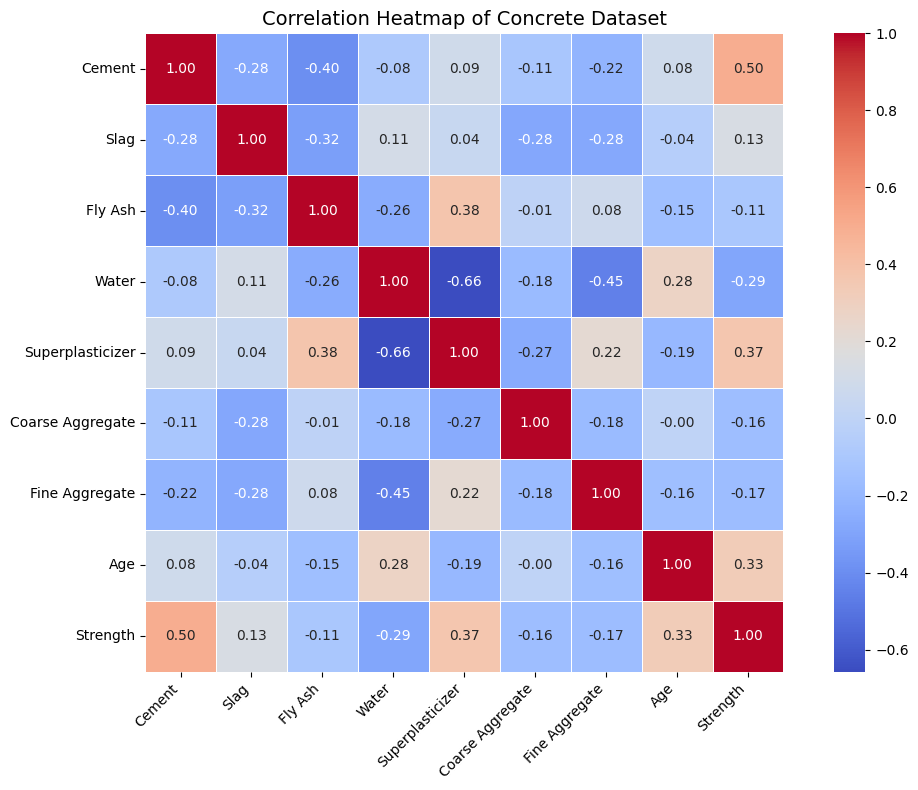

In [ ]:
# Short names for the heatmap
short_names = [
    'Cement', 'Slag', 'Fly Ash', 'Water',
    'Superplasticizer', 'Coarse Aggregate',
    'Fine Aggregate', 'Age', 'Strength'
]

# Calculate correlations
correlation = df.corr()
correlation.index = short_names
correlation.columns = short_names

# Create heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title('Correlation Heatmap of Concrete Dataset', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Correlation Analysis Findings

The heatmap shows that cement has the strongest positive correlation with concrete strength (0.50). Superplasticizer (0.37) and curing age (0.33) also have positive correlations, while water has a negative correlation (-0.29).

These results suggest that concrete strength depends on several factors. Therefore, using multiple features in machine learning may help improve the predictions.

## 4. Data Preprocessing

Before training the models, I will prepare the dataset by checking duplicate records and making the column names shorter and easier to use.

In [ ]:
# Create a copy of the original dataset
df_clean = df.copy()

# Rename columns
df_clean.columns = [
    'Cement', 'Slag', 'Fly Ash', 'Water',
    'Superplasticizer', 'Coarse Aggregate',
    'Fine Aggregate', 'Age', 'Strength'
]

# Check duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())

# Display some duplicate records
df_clean[df_clean.duplicated(keep=False)].head(10)

Duplicate rows: 25


,Cement,Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
72,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.398217
77,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.398217
80,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.398217
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
95,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.201007
100,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.201007
103,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.201007


### 4.1 Removing Duplicate Records

The dataset contains 25 exact duplicate rows. I will remove these duplicates to avoid repeated identical records affecting the machine learning models. The original dataset will remain unchanged.

In [ ]:
# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Check the dataset after cleaning
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

# Display the first 5 rows
df_clean.head()

Original dataset: (1030, 9)
Cleaned dataset: (1005, 9)
Remaining duplicates: 0


,Cement,Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


### Data Cleaning Results

After removing 25 exact duplicate rows, the dataset contains 1,005 samples and 9 columns. There are no missing values or remaining exact duplicates. The cleaned dataset will be used for machine learning.

### 4.2 Separating Features and Target Variable

I will separate the eight input features from the target variable. The input features describe the concrete mixture and curing age, while the target variable represents the compressive strength.

In [ ]:
# Separate input features and target variable

X = df_clean.drop('Strength', axis=1)
y = df_clean['Strength']

# Display the shapes
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

# Display feature names
print("\nInput features:")
print(X.columns.tolist())

Input features shape: (1005, 8)
Target variable shape: (1005,)

Input features:
['Cement', 'Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age']


### 4.3 Training and Testing Split

I will divide the cleaned dataset into approximately 80% training data and 20% testing data.

The training data will be used to train the machine learning models, while the testing data will evaluate their performance on unseen concrete mixtures.

Samples with the same mixture ingredients will be kept in the same set to avoid data leakage.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Group samples with the same concrete mixture
groups = pd.util.hash_pandas_object(
    X.drop(columns='Age'), index=False
)

# Split into training and testing sets
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Display the results
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

# Check that mixtures are not shared
print("No shared mixtures:",
      set(groups.iloc[train_idx]).isdisjoint(
          set(groups.iloc[test_idx])
      ))

Training samples: 821
Testing samples: 184
Training features: 8
Testing features: 8
No shared mixtures: True


### Training and Testing Split Results

The cleaned dataset was divided into 821 training samples and 184 testing samples. Both sets contain eight input features. The split was performed by grouping concrete mixtures to prevent identical ingredient combinations from appearing in both sets.

## 5. Machine Learning Models

### 5.1 Linear Regression

Linear Regression is the first model used in this project. It predicts concrete compressive strength based on the eight input features.

I selected this model because it is simple and provides a baseline for comparison with more advanced machine learning models.

In [ ]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

# Make predictions on training data
train_predictions = linear_model.predict(X_train)

# Compare the first 5 actual and predicted values
results = pd.DataFrame({
    'Actual Strength (MPa)': y_train.iloc[:5].values,
    'Predicted Strength (MPa)': train_predictions[:5]
})

results.round(2)

Linear Regression model trained successfully!


,Actual Strength (MPa),Predicted Strength (MPa)
0,79.99,53.29
1,61.89,53.53
2,40.27,56.83
3,41.05,67.50
4,44.30,60.14


### 5.2 Linear Regression Evaluation

I will evaluate the Linear Regression model using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

First, I will calculate these metrics using the training data to understand how well the model fits the data.

In [ ]:
# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate training performance
mae = mean_absolute_error(y_train, train_predictions)
rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
r2 = r2_score(y_train, train_predictions)

# Display results
print("Linear Regression - Training Results")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 3))

Linear Regression - Training Results
MAE: 8.15
RMSE: 10.29
R² Score: 0.606


### Linear Regression Training Results

The Linear Regression model achieved an MAE of 8.15 MPa, RMSE of 10.29 MPa, and R² score of 0.606 on the training data.

The results show that the model can explain some of the variation in concrete strength, but its predictions still have errors. A more advanced model may provide better results.

### 5.3 Linear Regression Cross-Validation

I will use 5-fold grouped cross-validation to evaluate how well Linear Regression performs on unseen concrete mixtures.

This will help me understand whether the model can generalize to new data before comparing it with Random Forest.

In [ ]:
from sklearn.model_selection import GroupKFold, cross_validate

# Create 5-fold grouped cross-validation
cv = GroupKFold(n_splits=5)

# Evaluate Linear Regression
cv_results = cross_validate(
    linear_model,
    X_train,
    y_train,
    groups=groups.iloc[train_idx],
    cv=cv,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'RMSE': 'neg_root_mean_squared_error',
        'R2': 'r2'
    }
)

# Calculate average results
print("Linear Regression - Cross-Validation Results")
print("Average MAE:", round(-cv_results['test_MAE'].mean(), 2))
print("Average RMSE:", round(-cv_results['test_RMSE'].mean(), 2))
print("Average R²:", round(cv_results['test_R2'].mean(), 3))

Linear Regression - Cross-Validation Results
Average MAE: 8.31
Average RMSE: 10.53
Average R²: 0.579


### Linear Regression Cross-Validation Findings

The Linear Regression model achieved an average MAE of 8.31 MPa, RMSE of 10.53 MPa, and R² score of 0.579.

The cross-validation results are close to the training results, which suggests that the model is not strongly overfitting. However, the prediction errors are still relatively high, so I will compare it with Random Forest to see if I can get better results.

### 5.4 Random Forest Regression

Random Forest is the second machine learning model used in this project. It combines multiple decision trees to make predictions.

I selected Random Forest because it can capture complex relationships between concrete ingredients, curing age, and compressive strength.

I will compare its performance with Linear Regression to determine which model predicts concrete strength more accurately.

In [ ]:
# Import Random Forest
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

# Make predictions on training data
rf_train_predictions = rf_model.predict(X_train)

# Compare actual and predicted values
rf_results = pd.DataFrame({
    'Actual Strength (MPa)': y_train.iloc[:5].values,
    'Predicted Strength (MPa)': rf_train_predictions[:5]
})

rf_results.round(2)

Random Forest model trained successfully!


,Actual Strength (MPa),Predicted Strength (MPa)
0,79.99,71.52
1,61.89,65.22
2,40.27,40.57
3,41.05,41.37
4,44.30,43.33


### 5.5 Random Forest Evaluation

I will evaluate the Random Forest model using MAE, RMSE, and R².

First, I will calculate the training performance to see how well the model fits the training data. Later, I will use cross-validation to evaluate its performance on unseen concrete mixtures.

In [ ]:
# Calculate Random Forest training performance
rf_mae = mean_absolute_error(y_train, rf_train_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_train, rf_train_predictions))
rf_r2 = r2_score(y_train, rf_train_predictions)

# Display results
print("Random Forest - Training Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R² Score:", round(rf_r2, 3))

Random Forest - Training Results
MAE: 1.27
RMSE: 1.98
R² Score: 0.985


### Random Forest Training Results

The Random Forest model achieved an MAE of 1.27 MPa, RMSE of 1.98 MPa, and R² score of 0.985.

Random Forest performed much better than Linear Regression on the training data. However, the very high R² score may indicate overfitting, so I will use cross-validation to check its performance on unseen data.

### 5.6 Random Forest Cross-Validation

I will use 5-fold grouped cross-validation to evaluate Random Forest on unseen concrete mixtures.

This will help me check for overfitting and compare Random Forest with Linear Regression.

In [ ]:
# Evaluate Random Forest using 5-fold cross-validation
rf_cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    groups=groups.iloc[train_idx],
    cv=cv,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'RMSE': 'neg_root_mean_squared_error',
        'R2': 'r2'
    }
)

# Display average results
print("Random Forest - Cross-Validation Results")
print("Average MAE:", round(-rf_cv_results['test_MAE'].mean(), 2))
print("Average RMSE:", round(-rf_cv_results['test_RMSE'].mean(), 2))
print("Average R²:", round(rf_cv_results['test_R2'].mean(), 3))

Random Forest - Cross-Validation Results
Average MAE: 4.69
Average RMSE: 6.46
Average R²: 0.843


### Random Forest Cross-Validation Findings

The Random Forest model achieved an average MAE of 4.69 MPa, RMSE of 6.46 MPa, and R² score of 0.843.

The cross-validation results are lower than the training results, suggesting some overfitting. However, the model still performs well on unseen concrete mixtures.

### 5.7 Model Comparison

I will compare Linear Regression and Random Forest using their cross-validation results.

The comparison will help me select the better model for predicting concrete compressive strength.

In [ ]:
# Compare cross-validation results
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE (MPa)': [
        -cv_results['test_MAE'].mean(),
        -rf_cv_results['test_MAE'].mean()
    ],
    'RMSE (MPa)': [
        -cv_results['test_RMSE'].mean(),
        -rf_cv_results['test_RMSE'].mean()
    ],
    'R²': [
        cv_results['test_R2'].mean(),
        rf_cv_results['test_R2'].mean()
    ]
})

# Display the comparison table
comparison.round(3)

,Model,MAE (MPa),RMSE (MPa),R²
0,Linear Regression,8.306,10.525,0.579
1,Random Forest,4.689,6.463,0.843


### Model Comparison Findings

Random Forest performed better than Linear Regression in all three evaluation metrics.

Random Forest achieved a lower MAE (4.69 MPa), lower RMSE (6.46 MPa), and higher R² score (0.843).

These results show that Random Forest is more accurate for predicting concrete compressive strength. Therefore, I will select Random Forest for further improvement.

### 5.8 Random Forest Hyperparameter Tuning

I will use GridSearchCV to find better parameters for the Random Forest model.

I will experiment with the number of trees, maximum tree depth, and minimum samples per leaf.

The goal is to improve prediction accuracy and reduce overfitting.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define parameters to test
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10],
    'min_samples_leaf': [1, 2]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# Find the best parameters
grid_search.fit(
    X_train,
    y_train,
    groups=groups.iloc[train_idx]
)

# Display results
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation MAE:",
      round(-grid_search.best_score_, 2))

Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best Cross-Validation MAE: 4.66


### Hyperparameter Tuning Findings

GridSearchCV selected 200 trees, no maximum depth limit, and a minimum of 1 sample per leaf.

The tuned Random Forest achieved a cross-validation MAE of 4.66 MPa, compared to 4.69 MPa for the original model.

The improvement was small, but the tuned model showed slightly better prediction accuracy.

### 5.9 Original vs. Tuned Random Forest

I will compare the original and tuned Random Forest models using MAE, RMSE, and R².

This comparison will help me determine whether hyperparameter tuning improved the model's performance.

In [ ]:
# Get the tuned Random Forest model
tuned_rf = grid_search.best_estimator_

# Evaluate the tuned model
tuned_cv = cross_validate(
    tuned_rf,
    X_train,
    y_train,
    groups=groups.iloc[train_idx],
    cv=cv,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'RMSE': 'neg_root_mean_squared_error',
        'R2': 'r2'
    }
)

# Compare original and tuned models
tuning_comparison = pd.DataFrame({
    'Model': ['Original Random Forest', 'Tuned Random Forest'],
    'MAE (MPa)': [
        -rf_cv_results['test_MAE'].mean(),
        -tuned_cv['test_MAE'].mean()
    ],
    'RMSE (MPa)': [
        -rf_cv_results['test_RMSE'].mean(),
        -tuned_cv['test_RMSE'].mean()
    ],
    'R²': [
        rf_cv_results['test_R2'].mean(),
        tuned_cv['test_R2'].mean()
    ]
})

tuning_comparison.round(3)

,Model,MAE (MPa),RMSE (MPa),R²
0,Original Random Forest,4.689,6.463,0.843
1,Tuned Random Forest,4.661,6.450,0.843


### Tuning Comparison Findings

The tuned Random Forest performed slightly better than the original model. Its MAE decreased from 4.689 to 4.661 MPa, and RMSE decreased from 6.463 to 6.450 MPa.

Both models achieved an R² score of 0.843. Since the improvement was small, tuning did not make a major difference.

I will select the tuned Random Forest for final testing.

## 6. Final Model Evaluation

I will evaluate Linear Regression and the tuned Random Forest using the testing dataset.

The testing data contains 184 samples that were not used during training or hyperparameter tuning.

I will compare the models using MAE, RMSE, and R² to evaluate how well they predict unseen concrete mixtures.

In [ ]:
# Make predictions on the testing data
linear_test_pred = linear_model.predict(X_test)
rf_test_pred = tuned_rf.predict(X_test)

# Compare test results
test_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Tuned Random Forest'],
    'MAE (MPa)': [
        mean_absolute_error(y_test, linear_test_pred),
        mean_absolute_error(y_test, rf_test_pred)
    ],
    'RMSE (MPa)': [
        np.sqrt(mean_squared_error(y_test, linear_test_pred)),
        np.sqrt(mean_squared_error(y_test, rf_test_pred))
    ],
    'R²': [
        r2_score(y_test, linear_test_pred),
        r2_score(y_test, rf_test_pred)
    ]
})

# Display results
test_comparison.round(3)

,Model,MAE (MPa),RMSE (MPa),R²
0,Linear Regression,8.035,10.084,0.590
1,Tuned Random Forest,4.621,6.081,0.851


### Final Model Evaluation Findings

The tuned Random Forest performed better than Linear Regression on the testing dataset.

Random Forest achieved an MAE of 4.62 MPa, RMSE of 6.08 MPa, and R² score of 0.851.

The results show that Random Forest can predict concrete compressive strength with relatively good accuracy on unseen mixtures. Therefore, I selected the tuned Random Forest as the final model.

### 6.1 Actual vs. Predicted Strength

I will create a scatter plot to compare the actual concrete compressive strength values with the predictions made by the tuned Random Forest model.

This visualization will help me understand how close the predictions are to the actual values.

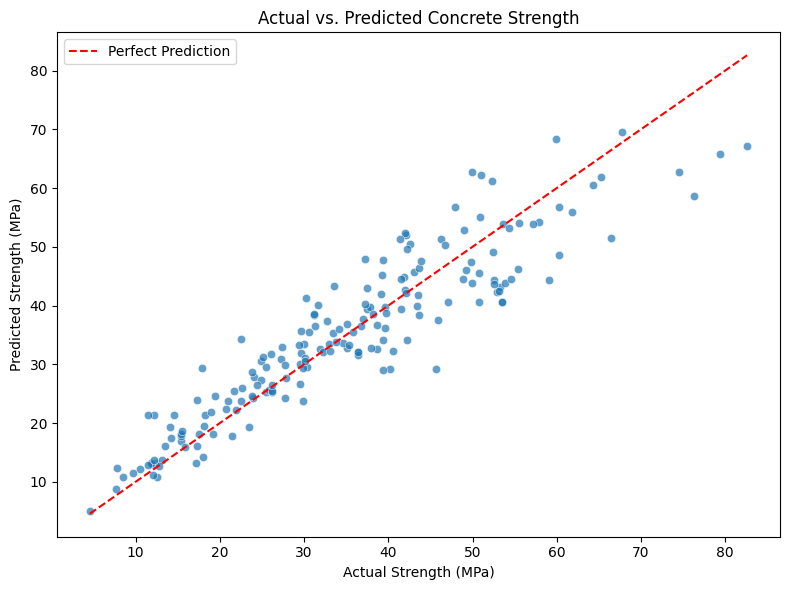

In [ ]:
# Actual vs. Predicted Strength

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=rf_test_pred,
    alpha=0.7
)

# Add a line for perfect predictions
min_val = min(y_test.min(), rf_test_pred.min())
max_val = max(y_test.max(), rf_test_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    label='Perfect Prediction'
)

plt.title('Actual vs. Predicted Concrete Strength')
plt.xlabel('Actual Strength (MPa)')
plt.ylabel('Predicted Strength (MPa)')
plt.legend()
plt.tight_layout()
plt.show()

### Actual vs. Predicted Strength Findings

The scatter plot shows that most predicted values are close to the actual concrete strength values.

However, some predictions have larger errors, especially for very high-strength concrete. The model tends to underestimate some of these values.

Overall, the plot shows that Random Forest provides reasonably accurate predictions, but there is still room for improvement.

### 6.2 Residual Analysis

I will examine the prediction errors of the tuned Random Forest model.

A residual plot will help me identify patterns in the errors and understand where the model performs well or poorly.

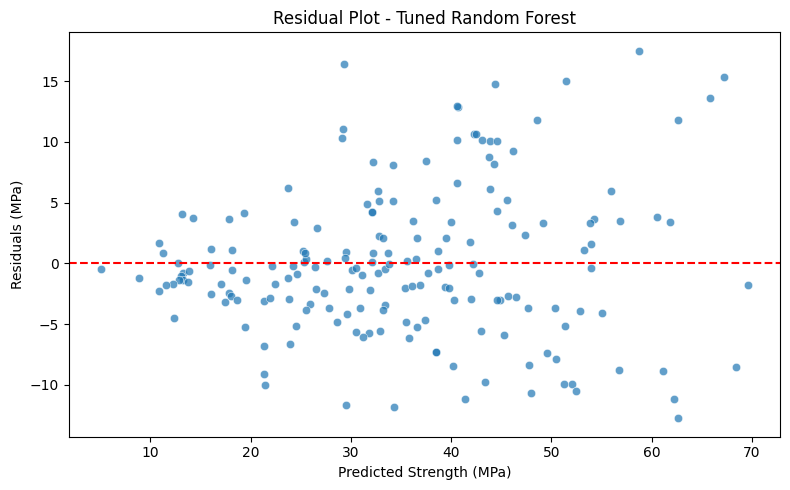

In [ ]:
# Calculate residuals
residuals = y_test - rf_test_pred

# Create residual plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=rf_test_pred,
    y=residuals,
    alpha=0.7
)

# Reference line at zero
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residual Plot - Tuned Random Forest')
plt.xlabel('Predicted Strength (MPa)')
plt.ylabel('Residuals (MPa)')

plt.tight_layout()
plt.show()

### Residual Analysis Findings

The residual plot shows that most prediction errors are distributed around zero. The errors are generally smaller at lower predicted strength values.

However, the residuals become more spread out at higher strength values, indicating that the model is less consistent for some stronger concrete samples.

Overall, Random Forest performs well, but some predictions still have large errors.

### 6.3 Prediction Errors by Strength Range

I will compare the prediction errors for different concrete strength ranges.

This analysis will help me identify where the model performs well and where its predictions are less accurate.

In [ ]:
# Create a table of actual values and prediction errors
error_analysis = pd.DataFrame({
    'Actual Strength': y_test.values,
    'Absolute Error': np.abs(y_test.values - rf_test_pred)
})

# Divide concrete strength into ranges
error_analysis['Strength Range'] = pd.cut(
    error_analysis['Actual Strength'],
    bins=[0, 20, 40, 60, np.inf],
    labels=['0-20', '20-40', '40-60', 'Above 60']
)

# Calculate average error for each range
range_results = error_analysis.groupby(
    'Strength Range', observed=True
)['Absolute Error'].agg(['count', 'mean'])

range_results.columns = ['Number of Samples', 'MAE (MPa)']

range_results.round(2)

,Number of Samples,MAE (MPa)
Strength Range,,
0-20,37,2.96
20-40,82,3.35
40-60,54,6.72
Above 60,11,9.40


### Prediction Error Analysis Findings

The model performs better for lower concrete strength values. The MAE is 2.96 MPa for strengths between 0–20 MPa and 3.35 MPa for 20–40 MPa.

However, the prediction errors increase for stronger concrete. The highest MAE is 9.40 MPa for strengths above 60 MPa.

This may be partly because the dataset has fewer high-strength concrete samples. Overall, the model performs well, but its predictions are less reliable for high-strength concrete.

### 6.4 Model Limitations and Possible Improvements

Although Random Forest achieved good results, the model has some limitations.

1. **High-strength concrete:** The model makes larger prediction errors for concrete above 60 MPa. There are fewer samples in this range, which may affect its performance.

2. **Overfitting:** The training R² score was higher than the cross-validation R² score, suggesting some overfitting.

3. **Dataset limitations:** The dataset contains 1,005 samples after cleaning. It does not include every factor that may affect concrete strength, such as curing temperature and humidity.

4. **Possible bias:** Because the dataset contains more samples in some strength ranges than others, the model may perform better for more common concrete strengths.

**Possible Improvements:**

- Collect more concrete samples, especially high-strength samples.
- Include additional information about curing conditions.
- Test other machine learning algorithms.
- Experiment with more hyperparameters to reduce overfitting.

Overall, the model provides useful strength predictions, but it should not replace actual laboratory testing for construction safety.

### 6.5 Feature Importance Analysis

I will analyze feature importance using the tuned Random Forest model.

This will help me understand which concrete ingredients and properties contribute most to the model's predictions.

In [ ]:
# Get feature importance from Random Forest
importance = tuned_rf.feature_importances_

# Create a feature importance table
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importance
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

# Display results
feature_importance.round(3)

,Feature,Importance
7,Age,0.356
0,Cement,0.318
3,Water,0.099
4,Superplasticizer,0.082
1,Slag,0.065
6,Fine Aggregate,0.035
5,Coarse Aggregate,0.027
2,Fly Ash,0.018


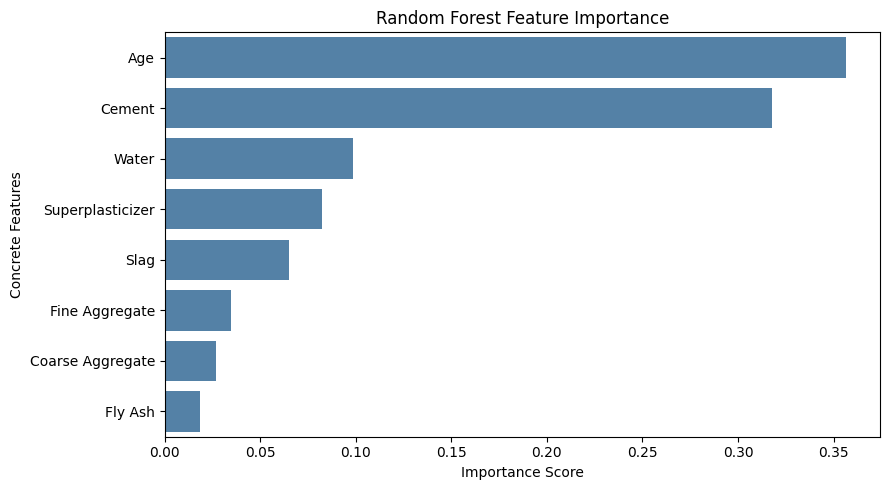

In [ ]:
# Plot feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    color='steelblue'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Concrete Features')

plt.tight_layout()
plt.show()

### Feature Importance Findings

The feature importance analysis shows that curing age (35.6%) and cement (31.8%) are the most important features in the Random Forest model.

Water (9.9%) and superplasticizer (8.2%) also contribute to the predictions, while fly ash has the lowest importance (1.8%).

These findings are reasonable because cement hydration and curing time affect concrete strength.

I decided to keep all eight features because they provide information about the concrete mixture and may help the model make better predictions.

## 7. Saving the Trained Model

I will save the final tuned Random Forest model so it can be loaded and used to predict concrete strength for new input data.

I will also save the feature names to make sure new inputs are provided in the correct order.

In [ ]:
# Import joblib
import joblib

# Save the trained model and feature names
model_data = {
    'model': tuned_rf,
    'feature_names': X_train.columns.tolist()
}

joblib.dump(model_data, 'concrete_strength_model.joblib')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
# Load the saved model
loaded_data = joblib.load('concrete_strength_model.joblib')

# Check the saved information
print("Model loaded successfully!")
print("Model:", type(loaded_data['model']).__name__)
print("Features:", loaded_data['feature_names'])

Model loaded successfully!
Model: RandomForestRegressor
Features: ['Cement', 'Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age']


## 8. Working Demonstration

In this section, I will demonstrate how the trained Random Forest model can predict concrete compressive strength using new input values.

The user will enter the amounts of concrete ingredients and curing age. The saved model will then predict the compressive strength in MPa.

This prediction can help estimate concrete strength before laboratory testing, but it does not replace actual strength testing.

In [ ]:
# Load the saved model and feature names
model = loaded_data['model']
feature_names = loaded_data['feature_names']

# Ask the user to enter concrete mixture values
new_values = []

for feature in feature_names:
    unit = 'days' if feature == 'Age' else 'kg/m3'
    value = float(input(f"Enter {feature} ({unit}): "))
    new_values.append(value)

# Prepare the input data
new_concrete = pd.DataFrame(
    [new_values],
    columns=feature_names
)

# Predict concrete strength
prediction = model.predict(new_concrete)

# Display the result
print("\nPredicted Concrete Compressive Strength:")
print(f"{prediction[0]:.2f} MPa")

Enter Cement (kg/m3): 300
Enter Slag (kg/m3): 100
Enter Fly Ash (kg/m3): 0
Enter Water (kg/m3): 180
Enter Superplasticizer (kg/m3): 8
Enter Coarse Aggregate (kg/m3): 950
Enter Fine Aggregate (kg/m3): 760
Enter Age (days): 28

Predicted Concrete Compressive Strength:
41.94 MPa


### Working Demonstration Results

I tested the saved Random Forest model using a new concrete mixture with a curing age of 28 days.

The model predicted a compressive strength of 41.94 MPa.

This demonstration shows that the trained model can accept new input values and predict concrete strength. However, the prediction is only an estimate and should not replace laboratory testing.

In [ ]:
# Download the saved model
from google.colab import files

files.download('concrete_strength_model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>